# 02 · Modelo econométrico de demanda de clubes de precio

**Objetivo:** estimar cuánto gasta un hogar en tiendas con membresía (Costco, Sam's, City Club) según sus características, y usar esa relación para calcular la demanda total de cada municipio y zona metropolitana candidata.

**Estrategia (modelo de dos partes, estándar en microeconometría del consumo):**

1. **¿El hogar compra en clubes?** Logit ponderado: $P(\text{compra}=1 \mid X) = \Lambda(X\beta)$.
2. **¿Cuánto gasta, si compra?** GLM Gamma con enlace logarítmico: $E[\text{gasto} \mid \text{compra}=1, X] = e^{X\gamma}$.
3. **Demanda esperada por hogar:** $E[\text{gasto} \mid X] = P(\cdot) \times E[\text{gasto} \mid \text{compra}=1]$.
4. **Modelo agregable (para proyectar a municipios):** MCO del gasto incondicional sobre $X$. Como es lineal, el promedio municipal se obtiene exacto: $\bar{G}_m = \hat{b}'\bar{X}_m$, con $\bar{X}_m$ tomado del Censo 2020.

Todas las estimaciones usan el factor de expansión de la ENIGH y errores estándar agrupados por unidad primaria de muestreo (`upm`), que es como recomienda INEGI tratar el diseño muestral.

**Variables explicativas (variables espejo ENIGH ↔ Censo):** automóvil, internet, computadora, horno de microondas, lavadora, TV de paga, tamaño del hogar y vivir en una localidad de 100 mil habitantes o más.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
# statsmodels avisa que los errores agrupados con freq_weights son aproximados; con pesos normalizados (media 1) el ajuste es adecuado
warnings.filterwarnings("ignore", message="cov_type not fully supported with freq_weights")

PROC = Path("../data/processed"); RES = Path("../resultados"); (RES / "graficos").mkdir(parents=True, exist_ok=True); (RES / "tablas").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COL = {"Guadalajara": "#2a6fdb", "Monterrey": "#d1495b", "Querétaro": "#2e9e6a"}

df = pd.read_csv(PROC / "hogares_enigh.csv", dtype={"folioviv": str, "foliohog": str, "entidad": str, "ubica_geo": str})
df["w"] = df["factor"] / df["factor"].mean()          # pesos normalizados (media 1)
df["ing_miles"] = df["ing_anual"] / 1000
X_VARS = ["auto", "internet", "computadora", "microondas", "lavadora", "tv_paga_d", "tam_hogar", "urbano_100k"]
NOMBRES = {"auto": "Automóvil", "internet": "Internet", "computadora": "Computadora", "microondas": "Microondas",
           "lavadora": "Lavadora", "tv_paga_d": "TV de paga", "tam_hogar": "Tamaño del hogar", "urbano_100k": "Localidad ≥100 mil hab."}
f_x = " + ".join(X_VARS)
print(f"Hogares: {len(df):,} | compran en clubes: {df.usa_club.sum():,} ({np.average(df.usa_club, weights=df.factor):.1%} ponderado)")

Hogares: 90,102 | compran en clubes: 7,425 (8.4% ponderado)


## 1. Evidencia descriptiva: el club de precios es un bien de hogares de ingreso alto

Antes de modelar, vemos cómo cambian la participación y el gasto por decil de ingreso.

In [2]:
def deciles(s, w, n=10):
    orden = np.argsort(s.values); cw = np.cumsum(w.values[orden].astype(float)); cw = cw / cw[-1]
    d = np.empty(len(s), int); d[orden] = np.minimum((cw * n).astype(int), n - 1) + 1
    return d
df["decil"] = deciles(df["ing_anual"], df["factor"])
tab_dec = df.groupby("decil").apply(lambda s: pd.Series({
    "ingreso_anual_prom": np.average(s.ing_anual, weights=s.factor),
    "pct_compra_club": np.average(s.usa_club, weights=s.factor) * 100,
    "gasto_club_prom": np.average(s.gasto_club, weights=s.factor),
    "gasto_club_si_compra": np.average(s.gasto_club[s.usa_club == 1], weights=s.factor[s.usa_club == 1]) if s.usa_club.sum() else np.nan,
}), include_groups=False).round(1)
tab_dec.to_csv(RES / "tablas/02_deciles_ingreso.csv")
tab_dec

,ingreso_anual_prom,pct_compra_club,gasto_club_prom,gasto_club_si_compra
decil,,,,
1,53636.0,1.0,86.9,8932.8
2,89680.4,1.4,97.5,7195.8
3,116800.9,1.9,164.3,8469.3
4,143784.3,2.8,249.4,8776.4
5,173361.0,4.2,475.9,11247.7
6,207695.8,5.2,622.9,11895.9
7,249640.1,7.2,986.6,13663.6
8,306936.0,10.8,1726.7,16036.9
9,403461.8,17.7,3245.8,18379.6


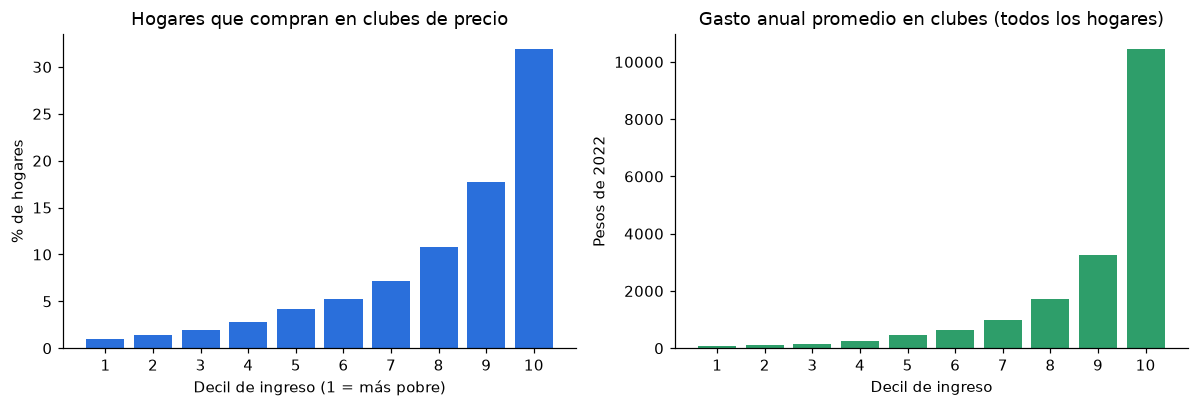

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(tab_dec.index, tab_dec.pct_compra_club, color="#2a6fdb")
ax[0].set(title="Hogares que compran en clubes de precio", xlabel="Decil de ingreso (1 = más pobre)", ylabel="% de hogares")
ax[1].bar(tab_dec.index, tab_dec.gasto_club_prom, color="#2e9e6a")
ax[1].set(title="Gasto anual promedio en clubes (todos los hogares)", xlabel="Decil de ingreso", ylabel="Pesos de 2022")
for a in ax: a.set_xticks(range(1, 11))
plt.tight_layout(); plt.savefig(RES / "graficos/02_deciles.png", bbox_inches="tight"); plt.show()

## 2. Propensión marginal y elasticidad ingreso del gasto en clubes

- **Propensión marginal a gastar en clubes (PMg):** de cada peso adicional de ingreso, ¿cuántos centavos van a clubes de precio? Es el coeficiente de una regresión lineal del gasto en clubes sobre el ingreso.
- **Elasticidad ingreso** (solo hogares que compran): regresión log-log. Si es mayor que 0, es un bien normal; si es mayor que 1, es un bien de lujo.

In [4]:
pmg = smf.wls("gasto_club ~ ing_miles", data=df, weights=df.w).fit(cov_type="cluster", cov_kwds={"groups": df.upm})
compradores = df[(df.usa_club == 1) & (df.ing_anual > 0)].copy()
elas = smf.wls(f"np.log(gasto_club) ~ np.log(ing_anual) + tam_hogar + urbano_100k", data=compradores, weights=compradores.w) \
          .fit(cov_type="cluster", cov_kwds={"groups": compradores.upm})

filas = [("Nacional", pmg.params["ing_miles"] / 1000, pmg.bse["ing_miles"] / 1000)]
for e, n in {"14": "Jalisco", "19": "Nuevo León", "22": "Querétaro"}.items():
    s = df[df.entidad == e]
    r = smf.wls("gasto_club ~ ing_miles", data=s, weights=s.w).fit(cov_type="cluster", cov_kwds={"groups": s.upm})
    filas.append((n, r.params["ing_miles"] / 1000, r.bse["ing_miles"] / 1000))
pmg_tab = pd.DataFrame(filas, columns=["ámbito", "PMg (pesos por peso de ingreso)", "error estándar"])
pmg_tab["centavos por cada peso adicional"] = (pmg_tab.iloc[:, 1] * 100).round(2)
pmg_tab.to_csv(RES / "tablas/02_propension_marginal.csv", index=False)
print(f"Elasticidad ingreso del gasto en clubes (compradores): {elas.params['np.log(ing_anual)']:.3f} "
      f"(EE {elas.bse['np.log(ing_anual)']:.3f}, p = {elas.pvalues['np.log(ing_anual)']:.4f})")
pmg_tab

Elasticidad ingreso del gasto en clubes (compradores): 0.653 (EE 0.038, p = 0.0000)


,ámbito,PMg (pesos por peso de ingreso),error estándar,centavos por cada peso adicional
0,Nacional,0.013536,0.004400,1.35
1,Jalisco,0.011317,0.002468,1.13
2,Nuevo León,0.007325,0.002118,0.73
3,Querétaro,0.016889,0.002719,1.69


## 3. Parte 1: ¿quién compra en clubes? (logit ponderado)

In [5]:
vif = pd.DataFrame({"variable": X_VARS,
                    "VIF": [variance_inflation_factor(sm.add_constant(df[X_VARS]).values, i + 1) for i in range(len(X_VARS))]}).round(2)
print("Multicolinealidad (VIF < 5 es aceptable):"); print(vif.to_string(index=False))

logit = smf.glm(f"usa_club ~ {f_x}", data=df, family=sm.families.Binomial(), freq_weights=df.w) \
           .fit(cov_type="cluster", cov_kwds={"groups": df.upm})
print(logit.summary())

Multicolinealidad (VIF < 5 es aceptable):
   variable  VIF
       auto 1.26
   internet 1.50
computadora 1.31
 microondas 1.29
   lavadora 1.25
  tv_paga_d 1.14
  tam_hogar 1.05
urbano_100k 1.15


                 Generalized Linear Model Regression Results                  
Dep. Variable:               usa_club   No. Observations:                90102
Model:                            GLM   Df Residuals:                    90093
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -21789.
Date:                Wed, 25 Nov 2026   Deviance:                       43578.
Time:                        20:08:00   Pearson chi2:                 9.03e+04
No. Iterations:                     7   Pseudo R-squ. (CS):            0.08947
Covariance Type:              cluster                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -4.9231      0.080    -61.371      

In [6]:
def efectos_marginales(modelo, data, variables, w):
    """Efecto marginal promedio (AME). Para dummies: diferencia de probabilidades 1 vs 0; para continuas: derivada."""
    out = {}
    for v in variables:
        if set(data[v].dropna().unique()) <= {0, 1}:
            d1, d0 = data.copy(), data.copy(); d1[v] = 1; d0[v] = 0
            out[v] = np.average(modelo.predict(d1) - modelo.predict(d0), weights=w)
        else:
            p = modelo.predict(data); out[v] = np.average(p * (1 - p), weights=w) * modelo.params[v]
    return pd.Series(out)

ame = efectos_marginales(logit, df, X_VARS, df.w)
tabla_logit = pd.DataFrame({"coeficiente": logit.params[X_VARS], "error estándar (cluster upm)": logit.bse[X_VARS],
                            "p-valor": logit.pvalues[X_VARS], "razón de momios": np.exp(logit.params[X_VARS]),
                            "efecto marginal (puntos %)": ame * 100}).rename(index=NOMBRES).round(4)
tabla_logit.to_csv(RES / "tablas/02_logit_participacion.csv")
tabla_logit

,coeficiente,error estándar (cluster upm),p-valor,razón de momios,efecto marginal (puntos %)
Automóvil,0.9969,0.0480,0.0,2.7098,6.2864
Internet,0.7530,0.0616,0.0,2.1233,4.4287
Computadora,0.7615,0.0411,0.0,2.1415,5.3648
Microondas,0.4012,0.0432,0.0,1.4937,2.6725
Lavadora,0.4527,0.0613,0.0,1.5725,2.7911
TV de paga,0.3093,0.0390,0.0,1.3624,2.1179
Tamaño del hogar,-0.0530,0.0121,0.0,0.9483,-0.3662
Localidad ≥100 mil hab.,0.6025,0.0482,0.0,1.8267,3.9797


### Bondad de ajuste y validación fuera de muestra

- **AUC (área bajo la curva ROC):** probabilidad de que el modelo asigne mayor probabilidad a un hogar comprador que a uno no comprador elegido al azar. 0.5 = azar, más de 0.7 = buena discriminación.
- **Validación cruzada en 5 partes:** se estima con 80% de los hogares y se evalúa en el 20% restante.
- **Calibración:** por decil de probabilidad predicha, la proporción observada debe parecerse a la predicha.

AUC dentro de muestra: 0.800 | AUC validación cruzada: 0.799 ± 0.004 | Pseudo R² McFadden: 0.162


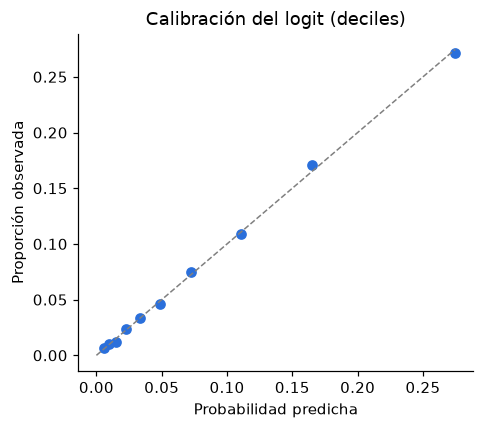

In [7]:
df["p_hat"] = logit.predict(df)
auc_in = roc_auc_score(df.usa_club, df.p_hat, sample_weight=df.w)
aucs = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(df, df.usa_club):
    m = smf.glm(f"usa_club ~ {f_x}", data=df.iloc[tr], family=sm.families.Binomial(), freq_weights=df.w.iloc[tr]).fit()
    aucs.append(roc_auc_score(df.usa_club.iloc[te], m.predict(df.iloc[te]), sample_weight=df.w.iloc[te]))
pseudo_r2 = 1 - logit.llf / logit.llnull
print(f"AUC dentro de muestra: {auc_in:.3f} | AUC validación cruzada: {np.mean(aucs):.3f} ± {np.std(aucs):.3f} | Pseudo R² McFadden: {pseudo_r2:.3f}")

df["dec_p"] = pd.qcut(df.p_hat, 10, labels=False) + 1
calib = df.groupby("dec_p").apply(lambda s: pd.Series({"predicha": np.average(s.p_hat, weights=s.w),
                                                        "observada": np.average(s.usa_club, weights=s.w)}), include_groups=False)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, calib.max().max()], [0, calib.max().max()], "--", color="grey", lw=1)
ax.scatter(calib.predicha, calib.observada, color="#2a6fdb")
ax.set(xlabel="Probabilidad predicha", ylabel="Proporción observada", title="Calibración del logit (deciles)")
plt.tight_layout(); plt.savefig(RES / "graficos/02_calibracion.png", bbox_inches="tight"); plt.show()

## 4. Parte 2: ¿cuánto gasta quien sí compra? (GLM Gamma, enlace log)

Los coeficientes se leen como semielasticidades: $e^{\gamma}-1$ es el cambio porcentual del gasto.

In [8]:
users = df[df.usa_club == 1].copy()
gamma = smf.glm(f"gasto_club ~ {f_x}", data=users, family=sm.families.Gamma(sm.families.links.Log()), freq_weights=users.w) \
           .fit(cov_type="cluster", cov_kwds={"groups": users.upm})
tabla_gamma = pd.DataFrame({"coeficiente": gamma.params[X_VARS], "error estándar": gamma.bse[X_VARS], "p-valor": gamma.pvalues[X_VARS],
                            "cambio % en gasto": (np.exp(gamma.params[X_VARS]) - 1) * 100}).rename(index=NOMBRES).round(4)
tabla_gamma.to_csv(RES / "tablas/02_gamma_intensidad.csv")
tabla_gamma

,coeficiente,error estándar,p-valor,cambio % en gasto
Automóvil,0.4062,0.0692,0.0000,50.1135
Internet,0.1106,0.0838,0.1871,11.6905
Computadora,0.3887,0.0655,0.0000,47.5133
Microondas,0.2179,0.0654,0.0009,24.3438
Lavadora,0.2552,0.0751,0.0007,29.0737
TV de paga,0.2149,0.0726,0.0031,23.9695
Tamaño del hogar,0.0239,0.0130,0.0649,2.4224
Localidad ≥100 mil hab.,0.1512,0.0665,0.0230,16.3257


## 5. Modelo agregable (MCO) para proyectar a municipios

Como el promedio de una función lineal es la función lineal del promedio, este modelo permite pasar del hogar al municipio sin sesgo de agregación. Verificamos que da la misma demanda que el modelo de dos partes.

In [9]:
ols = smf.wls(f"gasto_club ~ {f_x}", data=df, weights=df.w).fit(cov_type="cluster", cov_kwds={"groups": df.upm})
bp = sm.stats.het_breuschpagan(ols.resid, sm.add_constant(df[X_VARS]))
print(ols.summary().tables[1])
print(f"R² = {ols.rsquared:.3f} | Breusch-Pagan p = {bp[1]:.2e} (hay heterocedasticidad, por eso usamos errores robustos agrupados)")

df["g_2p"] = logit.predict(df) * gamma.predict(df)
df["g_ols"] = ols.predict(df)
comp = df.groupby("entidad").apply(lambda s: pd.Series({
    "observado": np.average(s.gasto_club, weights=s.w), "dos_partes": np.average(s.g_2p, weights=s.w),
    "MCO": np.average(s.g_ols, weights=s.w)}), include_groups=False)
print(f"Correlación entre estados (32): observado vs dos partes {comp.observado.corr(comp.dos_partes):.3f}, "
      f"observado vs MCO {comp.observado.corr(comp.MCO):.3f}, dos partes vs MCO {comp.dos_partes.corr(comp.MCO):.3f}")
tabla_ols = pd.DataFrame({"coeficiente (pesos/año)": ols.params, "error estándar": ols.bse, "p-valor": ols.pvalues}) \
               .rename(index=NOMBRES | {"Intercept": "Constante"}).round(3)
tabla_ols.to_csv(RES / "tablas/02_mco_agregable.csv")
comp.loc[["14", "19", "22"]].rename(index={"14": "Jalisco", "19": "Nuevo León", "22": "Querétaro"}).round(0)

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -1074.8596    163.016     -6.594      0.000   -1394.366    -755.353
auto         1695.7826    151.054     11.226      0.000    1399.721    1991.844
internet      -74.2408    126.346     -0.588      0.557    -321.874     173.392
computadora  2709.4028    337.076      8.038      0.000    2048.746    3370.059
microondas    817.6946    134.097      6.098      0.000     554.869    1080.520
lavadora       56.8737     59.372      0.958      0.338     -59.493     173.240
tv_paga_d    1099.7809    240.762      4.568      0.000     627.897    1571.665
tam_hogar     -13.4982     26.358     -0.512      0.609     -65.159      38.162
urbano_100k  1034.7150    188.134      5.500      0.000     665.980    1403.450
R² = 0.025 | Breusch-Pagan p = 4.03e-12 (hay heterocedasticidad, por eso usamos errores robustos agrupados)


Correlación entre estados (32): observado vs dos partes 0.786, observado vs MCO 0.799, dos partes vs MCO 0.986


,observado,dos_partes,MCO
entidad,,,
Jalisco,1932.0,2040.0,2179.0
Nuevo León,1859.0,2729.0,2650.0
Querétaro,3244.0,2212.0,2321.0


### Robustez: efecto de la oferta local

Si añadimos efectos fijos por estado, capturamos diferencias que **no** vienen de las características del hogar (por ejemplo, cuántos clubes hay cerca). El signo del efecto fijo de cada estado dice si sus hogares compran más o menos de lo que su perfil predice.

In [10]:
df["estado_cand"] = np.where(df.entidad.isin(["14", "19", "22"]), df.entidad, "resto")
fe = smf.glm(f"usa_club ~ {f_x} + C(estado_cand, Treatment('resto'))", data=df, family=sm.families.Binomial(), freq_weights=df.w) \
        .fit(cov_type="cluster", cov_kwds={"groups": df.upm})
fe_tab = fe.params.filter(like="estado_cand").to_frame("coeficiente").assign(p_valor=fe.pvalues.filter(like="estado_cand")).round(3)
fe_tab.index = ["Jalisco", "Nuevo León", "Querétaro"]
fe_tab

,coeficiente,p_valor
Jalisco,-0.143,0.134
Nuevo León,-0.290,0.003
Querétaro,0.220,0.005


## 6. Demanda municipal y por zona metropolitana

$$\text{Demanda}_{m,t} = \text{Hogares}_{m,t} \times \hat{G}_m \times \text{Inflación}_{2022\to t} \times k$$

- $\hat{G}_m = \hat{b}'\bar{X}_m$: gasto anual esperado por hogar con el perfil del municipio (Censo 2020).
- **Hogares 2026:** Censo 2020 proyectado con la tasa de crecimiento anual 2010-2020 de cada municipio (INEGI).
- **Inflación 2022→2026:** INPC 2023 4.7%, 2024 4.2%, 2025 3.7% (Walmex, *Informe 2025*, con datos de INEGI) y 2026 3.75% (Banxico SIE, INPC anual a octubre de 2026).
- **Calibración $k$:** la ENIGH capta solo compras de hogares (no de negocios con membresía) y subdeclara gasto. Se escala para que el total nacional coincida con las ventas reales de la industria en 2025: Costco México 104,328 millones de pesos (Expansión 500) + Sam's Club 21.6% de los ingresos de Walmex 2025 (1,011,598 millones; *Informe de sostenibilidad 2025* e *Informe anual 2025*). City Club se excluye por falta de cifras públicas, lo que hace la calibración conservadora. $k$ es igual para todas las zonas, así que **no cambia el orden** entre ellas.

In [11]:
cen = pd.read_csv(PROC / "municipios_censo.csv", dtype={"cve_mun": str, "entidad": str})
INFL = {2023: 0.047, 2024: 0.042, 2025: 0.037, 2026: 0.0375}
f_22_25 = np.prod([1 + INFL[a] for a in (2023, 2024, 2025)])
f_22_26 = f_22_25 * (1 + INFL[2026])

# Calibración nacional 2025
ventas_costco_mx_2025 = 104_328e6
ventas_sams_2025 = 0.216 * 1_011_598e6
industria_2025 = ventas_costco_mx_2025 + ventas_sams_2025
gasto_enigh_2022 = (df.gasto_club * df.factor).sum()
crec_hog_nal = 1.015 ** 3      # aprox. crecimiento de hogares 2022-2025; afecta solo el nivel, no el orden
k = industria_2025 / (gasto_enigh_2022 * f_22_25 * crec_hog_nal)
print(f"Industria 2025: {industria_2025/1e9:,.1f} mil millones | ENIGH llevada a 2025: {gasto_enigh_2022*f_22_25*crec_hog_nal/1e9:,.1f} | k = {k:.2f}")

cen["g_hogar_2022"] = ols.predict(cen[X_VARS])
cen["p_compra"] = logit.predict(cen[X_VARS])           # aproximación con perfil promedio (solo descriptiva)
cen["hogares_2026"] = cen.hogares_2020 * (1 + cen.tcma_hogares) ** 6
cen["demanda_2026"] = cen.hogares_2026 * cen.g_hogar_2022 * f_22_26 * k
cen.to_csv(PROC / "demanda_municipal.csv", index=False)

zm = cen.dropna(subset=["zona_metropolitana"]).groupby("zona_metropolitana").agg(
    hogares_2020=("hogares_2020", "sum"), hogares_2026=("hogares_2026", "sum"), demanda_2026=("demanda_2026", "sum"))
zm["tcma_hogares_2010_2020"] = (cen.dropna(subset=["zona_metropolitana"]).groupby("zona_metropolitana")
                                .apply(lambda s: (s.hogares_2020.sum() / s.hogares_2010.sum()) ** 0.1 - 1, include_groups=False))
zm["gasto_por_hogar_2026"] = zm.demanda_2026 / zm.hogares_2026
zm

Industria 2025: 322.8 mil millones | ENIGH llevada a 2025: 80.4 | k = 4.01


,hogares_2020,hogares_2026,demanda_2026,tcma_hogares_2010_2020,gasto_por_hogar_2026
zona_metropolitana,,,,,
Guadalajara,1483691.0,1.820564e+06,2.487095e+10,0.030704,13661.123842
Monterrey,1522975.0,2.077842e+06,2.713312e+10,0.035533,13058.313475
Querétaro,447579.0,6.078878e+05,9.572154e+09,0.049593,15746.580837


## 7. Oferta actual y demanda no atendida

Capacidad de venta de los clubes existentes (2025, llevada a 2026 con inflación):
- Costco: 104,328 / 42 tiendas = venta promedio por tienda en México.
- Sam's Club: 218,505 / 176 clubes (Walmex 2025).
- City Club: sin cifras públicas; se asume igual a un Sam's (supuesto conservador: sobreestima la competencia).

In [12]:
clubes = pd.read_csv(PROC / "clubes_precio.csv", dtype={"cve_mun": str})
venta_tienda = {"Costco": ventas_costco_mx_2025 / 42 * (1 + INFL[2026]),
                "Sam's Club": ventas_sams_2025 / 176 * (1 + INFL[2026])}
venta_tienda["City Club"] = venta_tienda["Sam's Club"]
clubes["capacidad_2026"] = clubes.cadena.map(venta_tienda)
oferta = clubes.dropna(subset=["zona_metropolitana"]).groupby("zona_metropolitana").agg(
    clubes=("cadena", "size"), costco=("cadena", lambda s: (s == "Costco").sum()), capacidad_2026=("capacidad_2026", "sum"))
zm = zm.join(oferta)
zm["demanda_no_atendida"] = zm.demanda_2026 - zm.capacidad_2026
zm["hogares_por_club"] = zm.hogares_2026 / zm.clubes
zm["indice_cobertura"] = zm.capacidad_2026 / zm.demanda_2026     # < 1: demanda supera oferta
zm["costcos_adicionales_que_cabe"] = zm.demanda_no_atendida / venta_tienda["Costco"]
tabla_zm = zm.copy()
for c in ["demanda_2026", "capacidad_2026", "demanda_no_atendida"]:
    tabla_zm[c] = tabla_zm[c] / 1e6
tabla_zm.round(2).to_csv(RES / "tablas/02_demanda_oferta_zm.csv")
tabla_zm[["hogares_2026", "tcma_hogares_2010_2020", "gasto_por_hogar_2026", "demanda_2026", "clubes", "costco",
          "capacidad_2026", "demanda_no_atendida", "indice_cobertura", "hogares_por_club", "costcos_adicionales_que_cabe"]].round(3)

,hogares_2026,tcma_hogares_2010_2020,gasto_por_hogar_2026,demanda_2026,clubes,costco,capacidad_2026,demanda_no_atendida,indice_cobertura,hogares_por_club,costcos_adicionales_que_cabe
zona_metropolitana,,,,,,,,,,,
Guadalajara,1820564.107,0.031,13661.124,24870.952,13,3,20612.081,4258.870,0.829,140043.393,1.653
Monterrey,2077842.449,0.036,13058.313,27133.118,19,4,29629.547,-2496.429,1.092,109360.129,-0.969
Querétaro,607887.793,0.050,15746.581,9572.154,6,2,10306.553,-734.398,1.077,101314.632,-0.285


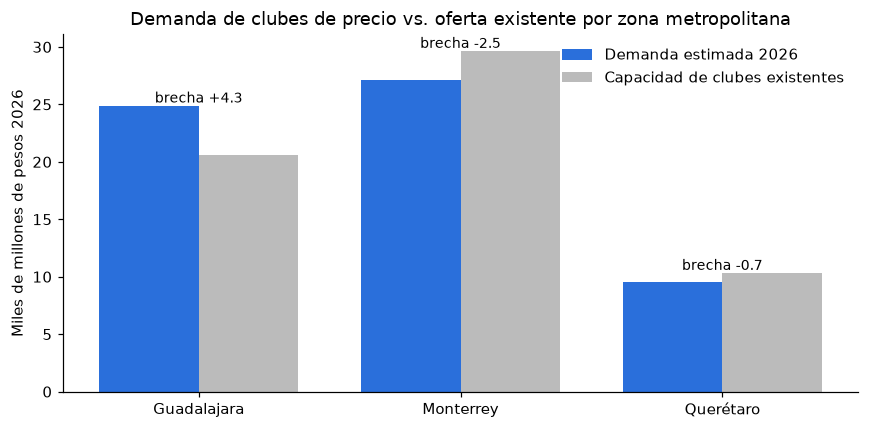

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(zm)); wd = 0.38
ax.bar(x - wd/2, zm.demanda_2026 / 1e9, wd, label="Demanda estimada 2026", color="#2a6fdb")
ax.bar(x + wd/2, zm.capacidad_2026 / 1e9, wd, label="Capacidad de clubes existentes", color="#bbbbbb")
for i, (d, c) in enumerate(zip(zm.demanda_2026, zm.capacidad_2026)):
    ax.annotate(f"brecha {(d-c)/1e9:+,.1f}", (i, max(d, c) / 1e9), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, zm.index); ax.set_ylabel("Miles de millones de pesos 2026"); ax.legend(frameon=False)
ax.set_title("Demanda de clubes de precio vs. oferta existente por zona metropolitana")
plt.tight_layout(); plt.savefig(RES / "graficos/02_brecha_zm.png", bbox_inches="tight"); plt.show()

### Prueba de robustez: demanda con efecto propio de cada estado

El logit con efectos fijos mostró que en Querétaro se compra **más** de lo que predice el perfil de sus hogares y en Nuevo León **menos**. Repetimos el cálculo de demanda con un MCO que incluye esos efectos fijos (escenario B). Si la zona ganadora cambia, la decisión no sería robusta.

In [14]:
ols_fe = smf.wls(f"gasto_club ~ {f_x} + C(estado_cand, Treatment('resto'))", data=df, weights=df.w)             .fit(cov_type="cluster", cov_kwds={"groups": df.upm})
efecto_estado = {"14": ols_fe.params.get("C(estado_cand, Treatment('resto'))[T.14]", 0),
                 "19": ols_fe.params.get("C(estado_cand, Treatment('resto'))[T.19]", 0),
                 "22": ols_fe.params.get("C(estado_cand, Treatment('resto'))[T.22]", 0)}
b = ols_fe.params
cen["g_hogar_2022_B"] = b["Intercept"] + (cen[X_VARS] * b[X_VARS]).sum(axis=1) + cen.entidad.map(efecto_estado)
cen["demanda_2026_B"] = cen.hogares_2026 * cen.g_hogar_2022_B * f_22_26 * k
zmB = cen.dropna(subset=["zona_metropolitana"]).groupby("zona_metropolitana").demanda_2026_B.sum().to_frame()
zmB = zmB.join(oferta[["capacidad_2026"]])
zmB["demanda_no_atendida_B"] = zmB.demanda_2026_B - zmB.capacidad_2026
zmB["indice_cobertura_B"] = zmB.capacidad_2026 / zmB.demanda_2026_B
robustez = pd.DataFrame({
    "Efecto estatal (pesos/hogar/año, 2022)": pd.Series(efecto_estado).rename({"14": "Guadalajara", "19": "Monterrey", "22": "Querétaro"}),
    "A · Brecha (millones)": zm.demanda_no_atendida / 1e6, "A · Cobertura": zm.indice_cobertura,
    "B · Brecha (millones)": zmB.demanda_no_atendida_B / 1e6, "B · Cobertura": zmB.indice_cobertura_B}).round(2)
robustez.to_csv(RES / "tablas/02_robustez_escenarios.csv")
robustez

,"Efecto estatal (pesos/hogar/año, 2022)",A · Brecha (millones),A · Cobertura,B · Brecha (millones),B · Cobertura
Guadalajara,-297.45,4258.87,0.83,2173.60,0.90
Monterrey,-852.56,-2496.43,1.09,-10298.18,1.53
Querétaro,882.29,-734.40,1.08,1931.70,0.84


## 8. ¿En qué municipio? Demanda local menos oferta local

Dentro de cada zona se ordena a los municipios por la demanda que **no** tiene un club en el mismo municipio. Es una aproximación: un club atiende a varios municipios vecinos.

In [15]:
cap_mun = clubes.groupby("cve_mun").capacidad_2026.sum()
n_mun = clubes.groupby("cve_mun").size()
mun = cen.dropna(subset=["zona_metropolitana"]).copy()
mun["clubes"] = mun.cve_mun.map(n_mun).fillna(0).astype(int)
mun["capacidad_2026"] = mun.cve_mun.map(cap_mun).fillna(0)
mun["brecha_local_mdp"] = (mun.demanda_2026 - mun.capacidad_2026) / 1e6
mun["demanda_mdp"] = mun.demanda_2026 / 1e6
top = (mun.sort_values("brecha_local_mdp", ascending=False).groupby("zona_metropolitana").head(4)
          [["zona_metropolitana", "municipio", "hogares_2026", "tcma_hogares", "auto", "g_hogar_2022", "demanda_mdp", "clubes", "brecha_local_mdp"]]
          .sort_values(["zona_metropolitana", "brecha_local_mdp"], ascending=[True, False]))
top.round(3).to_csv(RES / "tablas/02_municipios_candidatos.csv", index=False)
top.round(3)

,zona_metropolitana,municipio,hogares_2026,tcma_hogares,auto,g_hogar_2022,demanda_mdp,clubes,brecha_local_mdp
100,Guadalajara,Tonalá,187023.271,0.037,0.516,2607.781,2297.608,0,2297.608
38,Guadalajara,Guadalajara,416272.457,0.007,0.568,3508.193,6879.712,3,1726.436
97,Guadalajara,San Pedro Tlaquepaque,217785.712,0.027,0.551,3022.973,3101.507,2,525.381
69,Guadalajara,El Salto,85427.424,0.063,0.418,1067.043,429.426,0,429.426
142,Monterrey,García,222000.508,0.116,0.464,2331.380,2438.238,0,2438.238
130,Monterrey,Apodaca,220603.165,0.033,0.667,3529.847,3668.400,1,2380.337
155,Monterrey,Juárez,206954.373,0.075,0.461,2161.120,2106.990,0,2106.990
150,Monterrey,Guadalupe,190673.267,0.007,0.641,3609.904,3242.609,2,666.483
186,Querétaro,El Marqués,117549.551,0.096,0.585,2267.563,1255.710,0,1255.710
183,Querétaro,Huimilpan,11073.518,0.019,0.559,1098.474,57.304,0,57.304


## 9. Resultados que pasan a la evaluación financiera

In [16]:
salida = zm[["hogares_2026", "tcma_hogares_2010_2020", "demanda_2026", "capacidad_2026", "clubes", "costco"]].copy()
salida["venta_prom_costco_2026"] = venta_tienda["Costco"]
salida["venta_prom_sams_2026"] = venta_tienda["Sam's Club"]
salida["k_calibracion"] = k
salida["demanda_2026_B"] = zmB.demanda_2026_B
salida.to_csv(PROC / "insumos_financieros_zm.csv")
salida

,hogares_2026,tcma_hogares_2010_2020,demanda_2026,capacidad_2026,clubes,costco,venta_prom_costco_2026,venta_prom_sams_2026,k_calibracion,demanda_2026_B
zona_metropolitana,,,,,,,,,,
Guadalajara,1.820564e+06,0.030704,2.487095e+10,2.061208e+10,13,3,2.577150e+09,1.288063e+09,4.013542,2.278568e+10
Monterrey,2.077842e+06,0.035533,2.713312e+10,2.962955e+10,19,4,2.577150e+09,1.288063e+09,4.013542,1.933136e+10
Querétaro,6.078878e+05,0.049593,9.572154e+09,1.030655e+10,6,2,2.577150e+09,1.288063e+09,4.013542,1.223825e+10
